# Predicting the Best Mario Kart 8 Build for a Given Track

**Question:** given a Mario Kart 8 track's measurable properties (length, turns, elevation, terrain mix), can we predict the attributes of its community-agreed best build (driver + kart + tires + glider, 700k+ possible combinations)?

**Headline result:** after removing target leakage and recomputing build stats from a verified source, no model (RandomForest, SVR, GradientBoosting) beats a naive mean-prediction baseline on held-out tracks. See "Key insight" below for why -- it's a genuine, informative finding about this dataset, not a failed experiment.

## How the question was refined

- **Q1 -- "best combo given attribute priorities"**: fails, players don't understand how the five build attributes (speed, acceleration, handling, mini-turbo, traction) trade off against each other, so letting them specify priorities directly doesn't produce a usable interface.
- **Q2 -- "best combo given attribute values"**: this is just a lookup against existing combo data, not prediction -- there's no modelling problem here.
- **Q3 -- "best combo given a specific track"**: tracks are fixed and measurable (length, turns, elevation, terrain split), so this is a genuine supervised learning problem: predict the 5 target attributes of the track's best-known build from the track's features. This is what's modelled below.


## Dataset

52 Mario Kart 8 tracks, compiled by hand from in-game data and community sources. Columns: track length, turn count, average turn angle, elevation change, lap count, terrain composition (% off-road / road / water / anti-gravity), and the track's Community Best Combo (CBC) -- the character + kart body + tires + glider combination the community considers optimal, together with that build's 5 attribute values.

**Sources & credit**: track geometry measured from gameplay; build stats cross-checked against Luigi_Fan2's Mario Kart 8 stat chart (community reference, credited in `DATA_NOTICE.md`, not redistributed in this repo). Game names, characters and stats belong to Nintendo.

**Known data quality issue this notebook fixes**: the 52 rows were collected in two batches with incompatible encodings -- rows 1-31 use numeric terrain/elevation codes and an integer 3-5 build-stat scale, rows 32-52 use text labels and a decimal 1.75-4.5 scale. See `src/clean.py` for the full, documented fix (every decision has an inline comment explaining it). The cleaned output is committed at `data/mk8_tracks_clean.csv` so this notebook doesn't need to regenerate it to run -- regenerating requires a personal copy of the stat chart in `reference/` (gitignored, not part of this repo).


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.abspath(os.path.join('..', 'src')))
from evaluate import repeated_kfold_cv, summarize_cv, pooled_loto, TARGET_COLS

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style='whitegrid')

DATA_DIR = os.path.join('..', 'data')
IMAGES_DIR = os.path.join('..', 'images')
os.makedirs(IMAGES_DIR, exist_ok=True)


## 1. Loading the raw dataset

In [2]:
df_raw = pd.read_csv(os.path.join(DATA_DIR, 'mk8_tracks.csv'))
print(df_raw.shape)
df_raw.head()


(52, 38)


,Track Name,Terrain Type,Track Length (m),Turns,Lap Count,Elevation Changes,Avg. Turn Angle (°),Community Best Combo,CBC_Speed,CBC_Acceleration,...,CBC_Speed_Water,CBC_Acceleration_Water,CBC_Handling_Water,CBC_Traction_Water,CBC_MiniTurbo_Water,CBC_Speed_AntiGrav,CBC_Acceleration_AntiGrav,CBC_Handling_AntiGrav,CBC_Traction_AntiGrav,CBC_MiniTurbo_AntiGrav
0,Mario Kart Stadium,1,1600,8,3,5,45,Pink Yoshi + Cat Cruiser + Cushion + Paper Glider,4.0,4.0,...,4.0,4.0,3.0,3.0,4.0,NaN,NaN,NaN,NaN,NaN
1,Water Park,2,1800,10,3,0,30,White Yoshi + Mr. Scooty + Azure Roller + Pape...,3.0,5.0,...,3.0,4.0,4.0,3.0,3.0,5.0,NaN,NaN,NaN,NaN
2,Sweet Sweet Canyon,1,1900,12,3,0,25,Orange Yoshi + Mr. Scooty + Azure Roller + Pap...,3.0,5.0,...,3.0,4.0,4.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN
3,Thwomp Ruins,3,2100,15,3,10,35,Yellow Yoshi + Biddybuggy + Azure Roller + Pap...,4.0,4.0,...,5.0,4.0,4.0,4.0,4.0,3.0,4.0,NaN,NaN,NaN
4,Mario Circuit,1,1500,6,3,0,40,Pink Yoshi + Biddybuggy + Azure Roller + Paper...,3.0,5.0,...,3.0,5.0,4.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 38 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Track Name                 52 non-null     object 
 1   Terrain Type               52 non-null     object 
 2   Track Length (m)           52 non-null     int64  
 3   Turns                      52 non-null     int64  
 4   Lap Count                  52 non-null     int64  
 5   Elevation Changes          52 non-null     object 
 6   Avg. Turn Angle (°)        52 non-null     int64  
 7   Community Best Combo       52 non-null     object 
 8   CBC_Speed                  52 non-null     float64
 9   CBC_Acceleration           52 non-null     float64
 10  CBC_Handling               52 non-null     float64
 11  CBC_Mini Turbo             52 non-null     float64
 12  CBC_Traction               52 non-null     float64
 13  Average Speed (m/s)        52 non-null     float64
 

In [4]:
# Nulls only appear in the leaky terrain-split CBC_* columns (dropped below)
# and reflect 0% of that terrain on the track, e.g. a fully-landlocked track
# has no "water" build stats -- not missing data in the ordinary sense.
df_raw.isnull().sum()[df_raw.isnull().sum() > 0]


CBC_Traction_Water            8
CBC_MiniTurbo_Water          24
CBC_Speed_AntiGrav           27
CBC_Acceleration_AntiGrav    30
CBC_Handling_AntiGrav        31
CBC_Traction_AntiGrav        31
CBC_MiniTurbo_AntiGrav       31
dtype: int64

### Known issues in this raw file (see `src/clean.py` for the fixes)

1. **Two incompatible collection batches** (rows 1-31 vs 32-52): numeric vs text terrain/elevation codes, and two different `CBC_*` build-stat scales.
2. **Target leakage**: the 20 `CBC_*_OffRoad/_Road/_Water/_AntiGrav` columns are derived from the target `CBC_*` columns themselves (correlation 0.82-0.997) -- they must not be used as features.
3. **Build stats were hand-entered and inconsistent**: the same build (e.g. "Pink Yoshi + Biddybuggy + Azure Roller + Paper Glider") has different recorded stats on different tracks, even though build stats are deterministic given the parts. Recomputed from a verified source below.
4. **`Average Speed (m/s)`** is on two incompatible scales across the batches with no verifiable conversion factor (see Section 2.4) -- dropped.


## 2. Cleaning

Each fix below is implemented in `src/clean.py`; this section explains the reasoning and shows the effect. The full, already-cleaned file is loaded from `data/mk8_tracks_clean.csv` (produced by running `python src/clean.py` once).

### 2.1 Recomputing build stats from a verified source

Each row names an exact build (character + kart body + tires + glider), and build stats in MK8 are deterministic: `total = character_base + body_delta + tire_delta + glider_delta`. Rather than trust the hand-entered `CBC_*` columns, `src/clean.py` recomputes them from Luigi_Fan2's stat chart (`reference/mk8_stat_chart_luigi_fan2.xlsx`, not redistributed here), using the chart's documented equivalence groups to resolve character/kart-color variants and reskins to their shared stat-line.

**Caveat**: that chart documents the original Wii U Mario Kart 8, not Deluxe. Five rows use Deluxe-exclusive characters (Birdo, Funky Kong, Kamek x3, Peachette) and one uses a Deluxe-exclusive kart body (Inkstriker) -- 7 rows total, absent from the chart. These are flagged (`flag_target_unverified=1`) and keep their original, unrecomputed values rather than being guessed. They are excluded from model training below, but kept in the CSV for transparency.


In [5]:
df_clean = pd.read_csv(os.path.join(DATA_DIR, 'mk8_tracks_clean.csv'))
diff = pd.read_csv(os.path.join(DATA_DIR, 'mk8_cbc_recompute_diff.csv'))

n_total = len(df_clean)
n_flagged = int(df_clean['flag_target_unverified'].sum())
print(f"Rows: {n_total}  recomputed: {n_total - n_flagged}  flagged (Deluxe-only parts, unverified): {n_flagged}")
print(f"Of {n_total - n_flagged} recomputed rows, {len(diff)} had their CBC values change vs the raw CSV "
      f"(i.e. essentially all of them -- the hand-entered values were unreliable).")
diff[['Track Name', 'Build', 'CBC_Speed_old', 'CBC_Speed_new', 'CBC_Mini Turbo_old', 'CBC_Mini Turbo_new']].head(8)


Rows: 52  recomputed: 45  flagged (Deluxe-only parts, unverified): 7
Of 45 recomputed rows, 45 had their CBC values change vs the raw CSV (i.e. essentially all of them -- the hand-entered values were unreliable).


,Track Name,Build,CBC_Speed_old,CBC_Speed_new,CBC_Mini Turbo_old,CBC_Mini Turbo_new
0,Mario Kart Stadium,Pink Yoshi + Cat Cruiser + Cushion + Paper Glider,4.0,3.00,3.0,3.25
1,Water Park,White Yoshi + Mr. Scooty + Azure Roller + Pape...,3.0,2.00,4.0,5.00
2,Sweet Sweet Canyon,Orange Yoshi + Mr. Scooty + Azure Roller + Pap...,3.0,2.00,4.0,5.00
3,Thwomp Ruins,Yellow Yoshi + Biddybuggy + Azure Roller + Pap...,4.0,2.00,5.0,5.00
4,Mario Circuit,Pink Yoshi + Biddybuggy + Azure Roller + Paper...,3.0,2.00,3.0,5.00
5,Toad Harbor,Orange Yoshi + Varmint + Azure Roller + Paper ...,4.0,2.75,4.0,4.25
6,Twisted Mansion,Pink Yoshi + Mr. Scooty + Azure Roller + Paper...,3.0,2.00,4.0,5.00
7,Shy Guy Falls,Blue Yoshi + Teddy Buggy + Azure Roller + Pape...,4.0,2.75,4.0,4.00


In [6]:
target_cols_all = TARGET_COLS
n_unique_all = df_clean[target_cols_all].drop_duplicates().shape[0]
n_unique_modelled = df_clean[df_clean.flag_target_unverified == 0][target_cols_all].drop_duplicates().shape[0]
print(f"Unique target vectors across all {n_total} tracks: {n_unique_all}")
print(f"Unique target vectors among the {n_total - n_flagged} modelled (recomputed) tracks: {n_unique_modelled}")


Unique target vectors across all 52 tracks: 11
Unique target vectors among the 45 modelled (recomputed) tracks: 6


### 2.2 Terrain Type and Elevation Changes

- **Terrain Type** (numeric codes 1/2/3 in batch A vs text "Road"/"Anti-Gravity" in batch B): the two batches cover disjoint tracks, so there is no row to verify the code-to-label mapping against, and batch B never uses "Water" or "Off-Road" as a label at all -- codes 2 and 3 are unverifiable. Rather than guess, this column is **dropped entirely**: the `offroad_pct`/`road_pct`/`water_pct`/`antigrav_pct` columns already carry the same information continuously, without the ambiguity.
- **Elevation Changes** (0/5/10 vs Low/Moderate/High): this is ordinal with exactly 3 levels on each side, so `0->Low, 5->Moderate, 10->High` is the *only* order-preserving mapping -- not a guess about meaning, just the one consistent ordering. Encoded as `elevation_level` in {0, 1, 2}.
- **Terrain share columns** (plain numbers vs "NN%" strings): both represent the same 0-100 percent scale -- confirmed because rows sum to ~100 in 50 of 52 rows. This is a parsing fix, not a rescaling. The two exceptions (`N64 Rainbow Road` sums to 105, `Big Blue` sums to 200 -- listed as both 100% Water *and* 100% Anti-Grav, clearly a data entry error since the real track is 100% anti-gravity) are flagged (`flag_terrain_pct_invalid=1`) rather than silently corrected.


In [7]:
df_clean[df_clean.flag_terrain_pct_invalid == 1][['Track Name', 'offroad_pct', 'road_pct', 'water_pct', 'antigrav_pct']]


,Track Name,offroad_pct,road_pct,water_pct,antigrav_pct
31,N64 Rainbow Road,5.0,85.0,0.0,15.0
47,Big Blue,0.0,0.0,100.0,100.0


### 2.3 Dropped leaky features

The 20 `CBC_*_OffRoad/_Road/_Water/_AntiGrav` columns are removed -- they are derived from the targets, not independent track features.


### 2.4 Average Speed -- dropped, not rescaled

Batch A mean ~17.8 m/s, batch B mean ~9.4 m/s. This looked like a possible 2x unit conversion, but checking implied race duration (`track length * lap count / average speed`) shows batch A times (~220-365s) and batch B times (~79-534s) are already roughly comparable once track length is accounted for -- i.e. the raw speed difference is mostly explained by batch B's genuinely shorter tracks, not a fixed unit-scale bug. With no single verifiable conversion factor, this column is dropped rather than rescaled by guesswork. Section 6 (appendix) checks empirically whether including it anyway (unreconciled) would have changed anything.


## 3. Correlation matrix (cleaned features + targets)

Rows used for modelling: 45


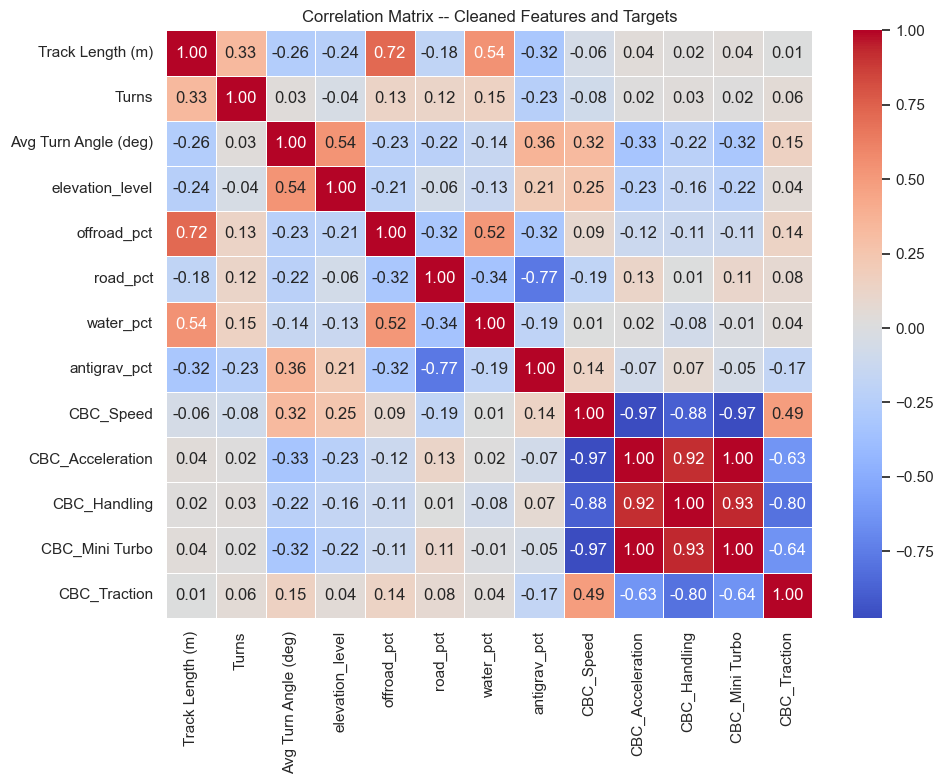

In [8]:
feature_cols = ['Track Length (m)', 'Turns', 'Avg Turn Angle (deg)', 'elevation_level',
                'offroad_pct', 'road_pct', 'water_pct', 'antigrav_pct']

df_model = df_clean[df_clean.flag_target_unverified == 0].reset_index(drop=True)
print(f"Rows used for modelling: {len(df_model)}")

corr_cols = feature_cols + TARGET_COLS
corr = df_model[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix -- Cleaned Features and Targets')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'correlation_matrix.png'), dpi=150)
plt.show()


## 4. Evaluation: repeated 5x10-fold cross-validation

With only 45 modelled rows, a single train/test split (what the original version of this notebook used) is extremely sensitive to which rows land in the test set. We use repeated K-fold CV (5 folds x 10 repeats = 50 fold-estimates per model/target) and report mean +/- std of R2 and MAE, against a `DummyRegressor(strategy="mean")` baseline. Random seed fixed throughout.


In [9]:
X = df_model[feature_cols]
y = df_model[TARGET_COLS]

cv_results = repeated_kfold_cv(X, y, n_splits=5, n_repeats=10, random_state=RANDOM_SEED)
summary = summarize_cv(cv_results)
summary_sorted = summary.sort_values(['target', 'model'])
summary_sorted


,model,target,mae_mean,mae_std,r2_mean,r2_std
0,Baseline (mean),CBC_Acceleration,0.538858,0.070904,-0.212883,0.246676
5,GradientBoosting,CBC_Acceleration,0.631241,0.129898,-1.177921,0.906537
10,RandomForest,CBC_Acceleration,0.570011,0.109796,-0.610080,0.611503
15,SVR (rbf),CBC_Acceleration,0.427016,0.145866,-0.239306,0.276985
1,Baseline (mean),CBC_Handling,0.205679,0.033822,-0.147156,0.165543
6,GradientBoosting,CBC_Handling,0.260541,0.050987,-1.185406,0.927252
11,RandomForest,CBC_Handling,0.240033,0.039257,-0.650131,0.635273
16,SVR (rbf),CBC_Handling,0.184512,0.048574,-0.084670,0.098542
2,Baseline (mean),CBC_Mini Turbo,0.441759,0.061469,-0.222311,0.275858
7,GradientBoosting,CBC_Mini Turbo,0.521277,0.100837,-1.213273,0.931862


**Reading this table**: for every target, every model's mean R2 is negative -- worse than always predicting the training-fold mean. None of RandomForest, SVR, or GradientBoosting beats the naive baseline once target leakage is removed. This is the honest result for this dataset at this size, not a tuning failure (see Section 7 for why).


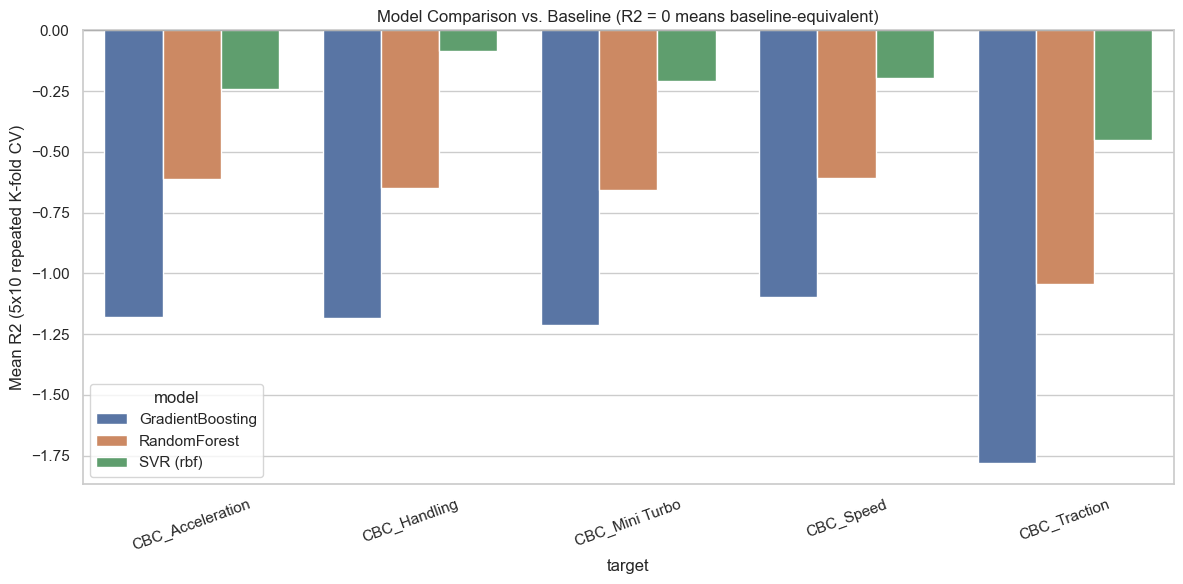

In [10]:
plt.figure(figsize=(12, 6))
plot_df = summary_sorted[summary_sorted['model'] != 'Baseline (mean)']
sns.barplot(data=plot_df, x='target', y='r2_mean', hue='model')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Mean R2 (5x10 repeated K-fold CV)')
plt.title('Model Comparison vs. Baseline (R2 = 0 means baseline-equivalent)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'model_comparison.png'), dpi=150)
plt.show()


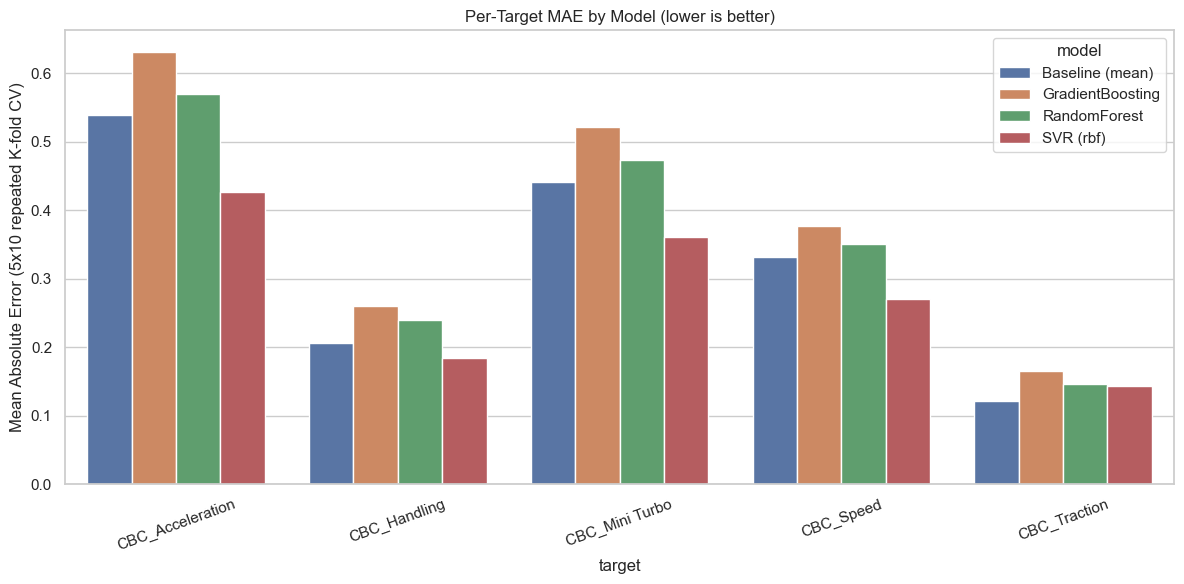

In [11]:
plt.figure(figsize=(12, 6))
sns.barplot(data=summary_sorted, x='target', y='mae_mean', hue='model')
plt.ylabel('Mean Absolute Error (5x10 repeated K-fold CV)')
plt.title('Per-Target MAE by Model (lower is better)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'per_target_error.png'), dpi=150)
plt.show()


## 5. Genuine held-out test: leave-one-track-out

The original notebook's "predict a new track" demo retrained on data that likely included the demo track, so it wasn't a real test. This section predicts every track's targets using a model trained on the *other 44* tracks only (pooled leave-one-out), then computes R2/MAE over all held-out predictions together -- a genuine single-track holdout, replicated 45 times.


In [12]:
loto_metrics, loto_preds = pooled_loto(X, y, df_model['Track Name'])
loto_metrics.sort_values(['target', 'model'])


,model,target,mae,r2
1,Baseline (mean),CBC_Acceleration,0.538384,-0.045971
16,GradientBoosting,CBC_Acceleration,0.666289,-0.908695
6,RandomForest,CBC_Acceleration,0.577111,-0.361312
11,SVR (rbf),CBC_Acceleration,0.425943,-0.160490
2,Baseline (mean),CBC_Handling,0.206061,-0.045971
17,GradientBoosting,CBC_Handling,0.271285,-0.839868
7,RandomForest,CBC_Handling,0.256667,-0.500481
12,SVR (rbf),CBC_Handling,0.184662,-0.019496
3,Baseline (mean),CBC_Mini Turbo,0.441414,-0.045971
18,GradientBoosting,CBC_Mini Turbo,0.543472,-0.895869


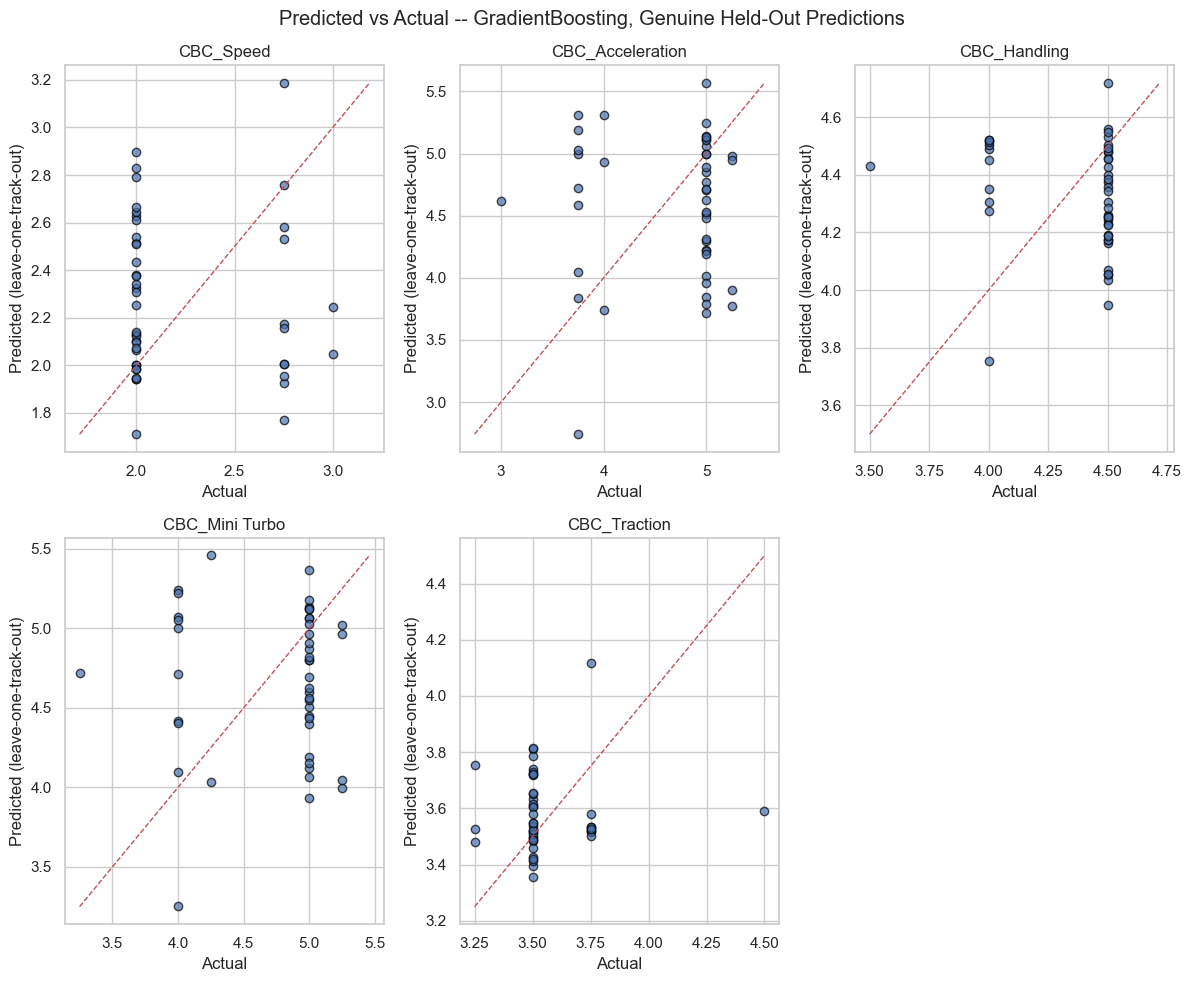

In [13]:
best_model_col = 'GradientBoosting_CBC_Speed_pred'
plt.figure(figsize=(12, 10))
for i, target in enumerate(TARGET_COLS):
    plt.subplot(2, 3, i + 1)
    actual = y[target].values
    pred = loto_preds[f'GradientBoosting_{target}_pred'].values
    plt.scatter(actual, pred, alpha=0.7, edgecolors='black')
    lims = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    plt.plot(lims, lims, 'r--', linewidth=1)
    plt.xlabel('Actual')
    plt.ylabel('Predicted (leave-one-track-out)')
    plt.title(target)
plt.suptitle('Predicted vs Actual -- GradientBoosting, Genuine Held-Out Predictions')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'predicted_vs_actual.png'), dpi=150)
plt.show()


## 6. Key insight: the target encodes player meta-bias, not an optimum

The "Community Best Combo" is the build players most commonly settle on, not a computed optimum -- and after fixing the duplicate-build inconsistency, there are only **6 distinct target vectors across the 45 modelled tracks** (one build, "Light-blue Yoshi + Biddybuggy + Azure Roller + Paper Glider", alone covers 7 of them). A small, heavily-Yoshi-biased set of community-favourite builds dominates regardless of track-specific features, which is largely why no model here beats the baseline: there isn't a strong learnable track -> build relationship in this target, there's a small number of popular builds applied broadly. Any "good" result on an unseen track in a model trained this way is more likely to reflect that popularity bias (e.g. predicting Yoshi-biddybuggy-style stats by default) than genuine track-driven optimization.


## 7. Appendix A: results before cleaning (for comparison only)

This reproduces the original notebook's evaluation approach on the raw, uncleaned data: features still include the 20 leaky `CBC_*_<Terrain>` columns (NaNs filled with 0 only to make the model runnable -- the original notebook would otherwise crash on this data), **and still include the other 4 target columns as features** when predicting each target (the original notebook dropped only `Average Speed`, not the targets, from its feature set). The near-perfect scores below are the direct result of that leakage, not a better model.


In [14]:
df_raw_numeric = df_raw.select_dtypes(include=['float64', 'int64']).drop(columns=['Lap Count'])
X_before = df_raw_numeric.drop(columns=['Average Speed (m/s)']).fillna(0)
y_before = df_raw_numeric[TARGET_COLS]

cv_before = repeated_kfold_cv(X_before, y_before, n_splits=5, n_repeats=10, random_state=RANDOM_SEED)
summary_before = summarize_cv(cv_before)

comparison = pd.merge(
    summary_before[['model', 'target', 'r2_mean', 'mae_mean']].rename(columns={'r2_mean': 'r2_before', 'mae_mean': 'mae_before'}),
    summary_sorted[['model', 'target', 'r2_mean', 'mae_mean']].rename(columns={'r2_mean': 'r2_after', 'mae_mean': 'mae_after'}),
    on=['model', 'target'], how='outer'
).sort_values(['target', 'model'])
comparison


,model,target,r2_before,mae_before,r2_after,mae_after
0,Baseline (mean),CBC_Acceleration,-0.123208,0.517706,-0.212883,0.538858
5,GradientBoosting,CBC_Acceleration,0.975279,0.026089,-1.177921,0.631241
10,RandomForest,CBC_Acceleration,0.973295,0.032865,-0.610080,0.570011
15,SVR (rbf),CBC_Acceleration,0.290946,0.360613,-0.239306,0.427016
1,Baseline (mean),CBC_Handling,-0.118303,0.490575,-0.147156,0.205679
6,GradientBoosting,CBC_Handling,0.968337,0.022941,-1.185406,0.260541
11,RandomForest,CBC_Handling,0.972697,0.023270,-0.650131,0.240033
16,SVR (rbf),CBC_Handling,0.277093,0.315591,-0.084670,0.184512
2,Baseline (mean),CBC_Mini Turbo,-0.110731,0.371041,-0.222311,0.441759
7,GradientBoosting,CBC_Mini Turbo,0.856513,0.055359,-1.213273,0.521277


**Before vs after, side by side**: before cleaning, GradientBoosting/RandomForest R2 is ~0.85-0.99 across every target -- this is target leakage, not model skill (the model is partly predicting each target from the other four targets, and from CBC_* columns derived from the targets). After cleaning, the same models score below baseline. The "after" numbers are the honest ones.


## 8. Appendix B: Average Speed inclusion -- sensitivity check

Section 2.4 dropped `Average Speed (m/s)` as unreconcilable across batches. Re-running the cleaned pipeline with the raw (unreconciled) column added back confirms it doesn't change the conclusion -- R2 remains negative throughout, consistent with Section 2.4's finding that the apparent scale difference is mostly explained by track length rather than a real unit bug worth recovering.


In [15]:
raw_speed = df_raw[['Track Name', 'Average Speed (m/s)']]
df_model_speed = df_model.merge(raw_speed, on='Track Name', how='left')
X_with_speed = df_model_speed[feature_cols + ['Average Speed (m/s)']]

cv_speed = repeated_kfold_cv(X_with_speed, y, n_splits=5, n_repeats=10, random_state=RANDOM_SEED)
summarize_cv(cv_speed).sort_values(['target', 'model'])


,model,target,mae_mean,mae_std,r2_mean,r2_std
0,Baseline (mean),CBC_Acceleration,0.538858,0.070904,-0.212883,0.246676
5,GradientBoosting,CBC_Acceleration,0.607250,0.143524,-1.011431,0.790396
10,RandomForest,CBC_Acceleration,0.553044,0.101083,-0.492514,0.534851
15,SVR (rbf),CBC_Acceleration,0.426984,0.145846,-0.239235,0.277034
1,Baseline (mean),CBC_Handling,0.205679,0.033822,-0.147156,0.165543
6,GradientBoosting,CBC_Handling,0.253386,0.062830,-1.048952,0.898524
11,RandomForest,CBC_Handling,0.236067,0.042545,-0.587118,0.490081
16,SVR (rbf),CBC_Handling,0.184492,0.048551,-0.084618,0.098441
2,Baseline (mean),CBC_Mini Turbo,0.441759,0.061469,-0.222311,0.275858
7,GradientBoosting,CBC_Mini Turbo,0.512338,0.115326,-1.113401,0.931413


## Limitations

- **52 tracks only** -- the full game (with all DLC) has 96. This dataset covers a subset, and 7 of the 52 have build targets that couldn't be verified against a Deluxe-accurate stat source (Section 2.1).
- **Recomputed build stats use the original Wii U Mario Kart 8 chart**, while the community builds themselves were chosen for Mario Kart 8 Deluxe, which patched some stat values after launch. Targets are internally consistent with each other (the main goal of recomputing them), but may not exactly match current live Deluxe numbers for every part.
- **The target is a community consensus, not a computed optimum**, and is dominated by a handful of popular builds (Section 6) -- this caps what any model can learn from 45 rows, regardless of algorithm.
- **Small-data overfitting risk**: 45 rows is little data for 5-target regression; CV mitigates but doesn't eliminate this.

## Next steps

- Complete all 96 tracks (including DLC), and recompute all 52 current rows (plus the 7 flagged) against a Mario Kart 8 **Deluxe**-accurate stat source rather than the original Wii U chart.
- Move from single-target regression to a **Pareto-frontier ranking** of builds per track, since "best" is better framed as a trade-off frontier across the 5 attributes than a single point prediction.
- A recommendation tool: given a track's measured features, surface the Pareto-optimal builds rather than one predicted vector.
